In [5]:
from pathlib import Path
from ultralytics import YOLO

# Caminho do modelo treinado
MODEL_PATH = Path("C:/Users/joaop/Downloads/GS2-ACV/firewatch_yolo12n_best.pt")

# Verificar existência
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Modelo não encontrado: {MODEL_PATH.resolve()}"
    )

# Carregar modelo
model = YOLO(str(MODEL_PATH))

print("Modelo carregado com sucesso!")
print("Classes:", model.names)

Modelo carregado com sucesso!
Classes: {0: 'Fire'}



image 1/1 C:\Users\joaop\Downloads\GS2-ACV\images (1).jpg: 448x640 2 Fires, 99.5ms
Speed: 1.9ms preprocess, 99.5ms inference, 1.1ms postprocess per image at shape (1, 3, 448, 640)


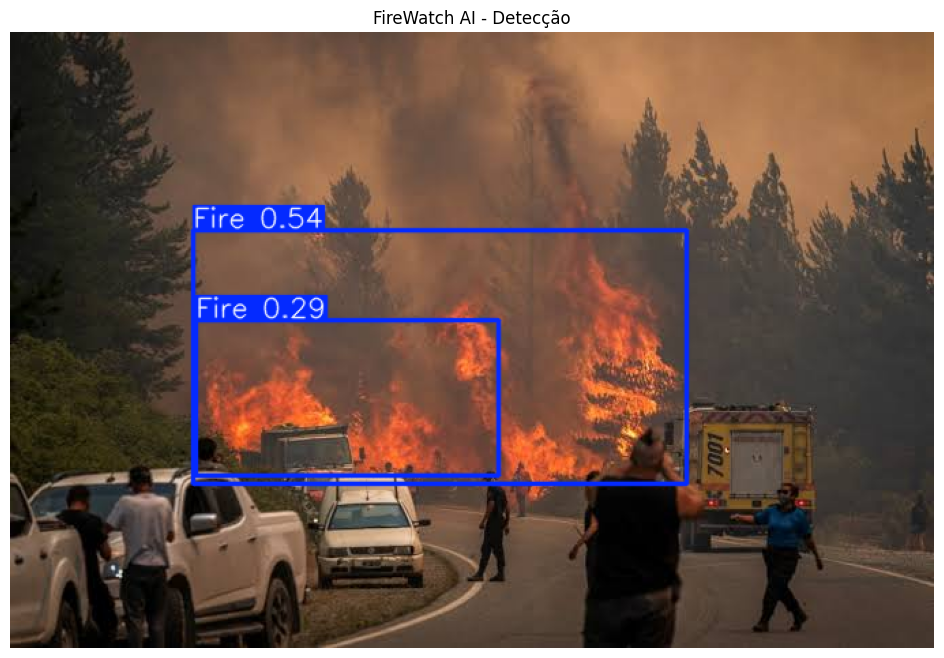

Classe: Fire | Confiança: 53.82%
Classe: Fire | Confiança: 28.72%


In [7]:
import cv2
import matplotlib.pyplot as plt
from tkinter import Tk, filedialog

# Abrir seletor de imagens
root = Tk()
root.withdraw()

imagem = filedialog.askopenfilename(
    title="Selecione uma imagem para analisar",
    filetypes=[
        ("Imagens", "*.jpg *.jpeg *.png *.webp")
    ]
)

root.destroy()

if imagem:
    resultados = model.predict(
        source=imagem,
        conf=0.25,
        imgsz=640
    )

    # Desenhar bounding boxes
    imagem_resultado = resultados[0].plot()

    # Converter BGR para RGB
    imagem_resultado = cv2.cvtColor(
        imagem_resultado,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 8))
    plt.imshow(imagem_resultado)
    plt.axis("off")
    plt.title("FireWatch AI - Detecção")
    plt.show()

    # Mostrar informações das detecções
    for caixa in resultados[0].boxes:
        classe = int(caixa.cls[0])
        confianca = float(caixa.conf[0])

        print(
            f"Classe: {model.names[classe]} | "
            f"Confiança: {confianca:.2%}"
        )
else:
    print("Nenhuma imagem selecionada.")

In [4]:
"""
FireWatch AI - Detecção de fogo e fumaça em vídeo
Requisitos: pip install ultralytics opencv-python
Coloque este arquivo em GS2-ACV/src/detectar_video.py
e os pesos em GS2-ACV/models/firewatch_yolo12n_best.pt.
Execute: python detectar_video.py
"""

from pathlib import Path
import sys
import cv2
from tkinter import Tk, filedialog
from ultralytics import YOLO

# Caminho calculado a partir da localização deste script.
MODEL_PATH = Path("C:/Users/joaop/Downloads/GS2-ACV/Model/firewatch_yolo12n_best.pt")

CONFIDENCE = 0.25
IMAGE_SIZE = 640
SHOW_PREVIEW = True


def selecionar_video():
    """Abre uma janela para selecionar o vídeo que será analisado."""
    root = Tk()
    root.withdraw()
    root.attributes("-topmost", True)
    caminho = filedialog.askopenfilename(
        title="Selecione um vídeo para analisar - FireWatch AI",
        filetypes=[
            ("Vídeos", "*.mp4 *.avi *.mov *.mkv *.wmv"),
            ("Todos os arquivos", "*.*"),
        ],
    )
    root.destroy()
    return Path(caminho) if caminho else None


def carregar_modelo():
    """Verifica e carrega os pesos treinados."""
    if not MODEL_PATH.is_file():
        raise FileNotFoundError(
            f"Modelo não encontrado em: {MODEL_PATH}\n"
            "Confira se o arquivo firewatch_yolo12n_best.pt está na pasta models."
        )

    print(f"Carregando modelo: {MODEL_PATH}")
    model = YOLO(str(MODEL_PATH))
    print("Modelo carregado com sucesso!")
    print("Classes:", model.names)
    return model


def processar_video(model, video_path):
    """Detecta objetos frame a frame e salva um novo vídeo anotado."""
    capture = cv2.VideoCapture(str(video_path))

    if not capture.isOpened():
        raise RuntimeError(f"Não foi possível abrir o vídeo: {video_path}")

    fps = capture.get(cv2.CAP_PROP_FPS)
    largura = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    altura = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))

    if fps <= 0:
        fps = 25.0
    if largura <= 0 or altura <= 0:
        capture.release()
        raise RuntimeError("Não foi possível identificar a resolução do vídeo.")

    output_path = video_path.with_name(f"{video_path.stem}_firewatch.mp4")
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(str(output_path), fourcc, fps, (largura, altura))

    if not writer.isOpened():
        capture.release()
        raise RuntimeError("Não foi possível criar o vídeo de saída.")

    frame_atual = 0
    print(f"\nAnalisando: {video_path.name}")
    print(f"Resolução: {largura}x{altura} | FPS: {fps:.2f}")
    print("Pressione Q ou ESC na janela de vídeo para interromper.")

    try:
        while True:
            sucesso, frame = capture.read()
            if not sucesso:
                break

            resultado = model.predict(
                source=frame,
                conf=CONFIDENCE,
                imgsz=IMAGE_SIZE,
                verbose=False,
            )[0]

            frame_anotado = resultado.plot()

            if frame_anotado.shape[1] != largura or frame_anotado.shape[0] != altura:
                frame_anotado = cv2.resize(frame_anotado, (largura, altura))

            writer.write(frame_anotado)
            frame_atual += 1

            if frame_atual % 30 == 0:
                if total_frames > 0:
                    percentual = frame_atual / total_frames * 100
                    print(f"Progresso: {frame_atual}/{total_frames} ({percentual:.1f}%)")
                else:
                    print(f"Frames processados: {frame_atual}")

            if SHOW_PREVIEW:
                cv2.imshow("FireWatch AI - Deteccao de fogo e fumaca", frame_anotado)
                tecla = cv2.waitKey(1) & 0xFF
                if tecla in (ord("q"), 27):
                    print("Processamento interrompido pelo usuário.")
                    break
    finally:
        capture.release()
        writer.release()
        if SHOW_PREVIEW:
            cv2.destroyAllWindows()

    print(f"\nConcluído! Frames processados: {frame_atual}")
    print(f"Vídeo com detecções salvo em:\n{output_path}")
    return output_path


def main():
    print("=" * 55)
    print("FIREWATCH AI - DETECÇÃO DE FOGO E FUMAÇA")
    print("=" * 55)

    try:
        model = carregar_modelo()
        video_path = selecionar_video()

        if video_path is None:
            print("Nenhum vídeo selecionado. Encerrando.")
            return

        processar_video(model, video_path)

    except Exception as erro:
        print(f"\nERRO: {erro}")
        sys.exit(1)


if __name__ == "__main__":
    main()


FIREWATCH AI - DETECÇÃO DE FOGO E FUMAÇA
Carregando modelo: C:\Users\joaop\Downloads\GS2-ACV\Model\firewatch_yolo12n_best.pt
Modelo carregado com sucesso!
Classes: {0: 'Fire'}

Analisando: video1.mp4
Resolução: 1280x720 | FPS: 30.00
Pressione Q ou ESC na janela de vídeo para interromper.
Progresso: 30/609 (4.9%)
Progresso: 60/609 (9.9%)
Progresso: 90/609 (14.8%)
Progresso: 120/609 (19.7%)
Progresso: 150/609 (24.6%)
Progresso: 180/609 (29.6%)
Progresso: 210/609 (34.5%)
Progresso: 240/609 (39.4%)
Progresso: 270/609 (44.3%)
Progresso: 300/609 (49.3%)
Progresso: 330/609 (54.2%)
Progresso: 360/609 (59.1%)
Processamento interrompido pelo usuário.

Concluído! Frames processados: 364
Vídeo com detecções salvo em:
C:\Users\joaop\Downloads\GS2-ACV\Teste\video1_firewatch.mp4
